# Test 6 — Select a justified social baseline

**Question.** What do Tests 1–5 justify, and are we ready for light-dependent speed?

**Why this is needed.** Successful execution, high polarization and a final connected frame are different kinds of evidence. Choosing whichever condition looks nicest can hide numerical problems or transfer fragmentation to different seeds.

**Changes and controls.** This notebook changes no dynamics and reruns no fitted condition. It compares saved results from matched-seed experiments, keeping their different physical horizons separate: 62.5 s for baseline/walls/extensions and 31.25 s for timestep comparisons.

**Hypotheses.** Finite interaction range may allow disconnected subgroups to persist, while wall responses, decision frequency and social assumptions may change assembly. Evidence may support both mechanisms rather than a single exclusive cause.

Run Tests 1–5 first. Their CSV evidence is read below in a fresh kernel.


In [1]:
from pathlib import Path
import sys

MODEL_DIR = next(
    folder for parent in (Path.cwd(), *Path.cwd().parents)
    for folder in (parent, parent / "papers")
    if (folder / "shiner_model.py").is_file() and (folder / "handlings").is_dir()
)
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))
HERE = MODEL_DIR / "handlings" / "trial_one"
STUDY_DIR = HERE

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

sys.path.insert(0, str(MODEL_DIR))
DATA_DIR = STUDY_DIR / "data"
FIGURE_DIR = STUDY_DIR / "figures"
baseline = pd.read_csv(DATA_DIR / "01_connectivity_case_summary.csv")
seed_details = pd.read_csv(DATA_DIR / "02_seed_summary.csv")
walls = pd.read_csv(DATA_DIR / "03_wall_case_summary.csv")
timesteps = pd.read_csv(DATA_DIR / "04_timestep_case_summary.csv")
grid_differences = pd.read_csv(DATA_DIR / "04_timestep_grid_differences.csv")
extensions = pd.read_csv(DATA_DIR / "social_extensions_summary.csv")
regression = json.loads((DATA_DIR / "implementation_regression.json").read_text())
assert len(baseline) == 10 and len(walls) == 6
assert len(timesteps) == 30 and len(extensions) == 50
assert regression["diagnostics_preserve_states_and_rng"]
assert extensions.groupby("Condition")["Seed"].nunique().eq(10).all()
print("Evidence loaded from the executed Tests 1–5; no model parameters are fitted here.")


Evidence loaded from the executed Tests 1–5; no model parameters are fitted here.


## Explicit decision conventions

For a provisional cohesion screen, require late mean largest-group fraction at least 0.95 and late connected-time fraction at least 0.90 in at least 9 of 10 matched seeds. These are diagnostic choices for this study, not biological constants. Passing the screen is insufficient without acceptable timestep sensitivity and high-speed resolution. Persistent fragmentation means at least 2.5 s; initial disconnection is reported separately from a split after cohesion.


In [2]:
# Decision conventions for this study, not biological constants.
MIN_LATE_LGF = 0.95
MIN_LATE_CONNECTED_FRACTION = 0.90
MIN_ACCEPTABLE_SEEDS = 9
extensions["MeetsLateCohesionConvention"] = (
    extensions["LateMeanLargestGroupFraction"].ge(MIN_LATE_LGF)
    & extensions["LateConnectedFraction"].ge(MIN_LATE_CONNECTED_FRACTION)
)
candidates = extensions.groupby("Condition", sort=False).agg(
    Seeds=("Seed", "nunique"),
    MeanLateLargestGroupFraction=("LateMeanLargestGroupFraction", "mean"),
    MeanLateConnectedFraction=("LateConnectedFraction", "mean"),
    SeedsMeetingLateCohesion=("MeetsLateCohesionConvention", "sum"),
    PersistentSplitEvents=("PersistentSplitEvents", "sum"),
    MeanPersistentFragmentedTimeFraction=("PersistentFragmentedTimeFraction", "mean"),
    MeanLatePolarization=("LatePolarization", "mean"),
)
final_counts = extensions.assign(Connected=extensions.FinalGroups.eq(1)).groupby("Condition")["Connected"].sum()
candidates["FinalConnectedSeeds"] = final_counts
candidates["MeetsSeedRobustnessConvention"] = candidates.SeedsMeetingLateCohesion.ge(MIN_ACCEPTABLE_SEEDS)
candidates.to_csv(DATA_DIR / "06_candidate_comparison.csv")
candidates.round(4)


,Seeds,MeanLateLargestGroupFraction,MeanLateConnectedFraction,SeedsMeetingLateCohesion,PersistentSplitEvents,MeanPersistentFragmentedTimeFraction,MeanLatePolarization,FinalConnectedSeeds,MeetsSeedRobustnessConvention
Condition,,,,,,,,,
A — Baseline,10,0.9309,0.753,7,0,0.4750,0.8723,8,False
B — FOV only,10,0.8840,0.606,5,1,0.5864,0.7931,7,False
C — Turning only,10,0.8850,0.700,7,1,0.5266,0.8276,7,False
D — Noise only,10,0.9441,0.865,8,1,0.4614,0.8909,9,False
E — Combined,10,0.8800,0.700,7,2,0.5080,0.8343,7,False


## Initial assembly and the wall comparison

Check initial component sizes and first-connected time before interpreting a final disconnected frame as a breakup. The 40×40 arena intervention translates the initial geometry instead of scattering fish at a new density; it controls local starting separations while altering wall distances and available space. It is not a wall-free or density-free experiment.


In [3]:
display(seed_details[["Seed", "InitialComponentSizes", "FirstConnectedTime_s", "ConnectedTimeFraction", "FinalComponentSizes", "PersistentSplitEvents"]])
display(walls[["Seed", "Arena", "FinalComponentSizes", "LateMeanLargestGroupFraction", "ConnectedTimeFraction", "ReflectedFishStepsPerSecond"]])
assert seed_details.loc[seed_details.Seed.isin([0, 2]), "FirstConnectedTime_s"].isna().all()
assert seed_details.loc[seed_details.Seed.isin([0, 2]), "ConnectedTimeFraction"].eq(0).all()


,Seed,InitialComponentSizes,FirstConnectedTime_s,ConnectedTimeFraction,FinalComponentSizes,PersistentSplitEvents
0,0,18+2,NaN,0.0,10+10,0
1,2,19+1,NaN,0.0,19+1,0
2,1,20,0.0,1.0,20,0


,Seed,Arena,FinalComponentSizes,LateMeanLargestGroupFraction,ConnectedTimeFraction,ReflectedFishStepsPerSecond
0,0,20 x 20,10+10,0.50,0.0,9.680
1,2,20 x 20,19+1,0.95,0.0,2.112
2,1,20 x 20,20,1.00,1.0,1.408
3,0,40 x 40 translated,10+10,0.50,0.0,3.648
4,2,40 x 40 translated,15+5,0.75,0.0,0.784
5,1,40 x 40 translated,20,1.00,1.0,0.784


## Equal-time numerical evidence

The timestep comparisons use five matched seeds, both speeds and the same 31.25-s physical horizon. Three tested timesteps are evidence of sensitivity, not a mathematical convergence proof. The geometric pass detector excludes wall-reflected segments, and so provides a restricted diagnostic rather than a complete collision count.


In [4]:
time_summary = timesteps.groupby(["Speed_BL_s", "Dt_s"]).agg(
    Runs=("Seed", "nunique"),
    MeanLateLargestGroupFraction=("LateMeanLargestGroupFraction", "mean"),
    MeanLateConnectedFraction=("LateConnectedFraction", "mean"),
    MeanLatePolarization=("LatePolarization", "mean"),
    MissedPassesPerSecond=("MissedPassesPerSecond", "mean"),
    ExactOverlapPairs=("ExactOverlapPairs", "sum"),
)
assert timesteps.Duration_s.eq(31.25).all()
display(time_summary.round(5))
display(grid_differences.groupby(["Speed_BL_s", "CandidateDt_s"])[
    ["LargestGroupFraction_MAE", "Polarization_MAE", "MeanDistanceToCentroid_MAE"]
].mean().round(5))


Runs  MeanLateLargestGroupFraction  \
Speed_BL_s Dt_s                                          
1.0        0.03125     5                        0.9700   
           0.06250     5                        0.8037   
           0.12500     5                        0.8200   
5.0        0.03125     5                        1.0000   
           0.06250     5                        1.0000   
           0.12500     5                        1.0000   

                    MeanLateConnectedFraction  MeanLatePolarization  \
Speed_BL_s Dt_s                                                       
1.0        0.03125                      0.600               0.92898   
           0.06250                      0.237               0.71447   
           0.12500                      0.400               0.75443   
5.0        0.03125                      1.000               0.94467   
           0.06250                      1.000               0.78538   
           0.12500                      1.000               0.47599   

                    MissedPassesPerSecond  ExactOverlapPairs  
Speed_BL_s Dt_s                                               
1.0        0.03125                 0.0000                  0  
           0.06250                 0.0000                  0  
           0.12500                 0.0064                  0  
5.0        0.03125                 0.0896                  0  
           0.06250                 1.0368                  0  
           0.12500                11.4048                  0

LargestGroupFraction_MAE  Polarization_MAE  \
Speed_BL_s CandidateDt_s                                               
1.0        0.0625                          0.10271           0.21061   
           0.1250                          0.11367           0.20270   
5.0        0.0625                          0.03450           0.21197   
           0.1250                          0.06295           0.41469   

                          MeanDistanceToCentroid_MAE  
Speed_BL_s CandidateDt_s                              
1.0        0.0625                            1.86430  
           0.1250                            2.01695  
5.0        0.0625                            0.79337  
           0.1250                            1.11429

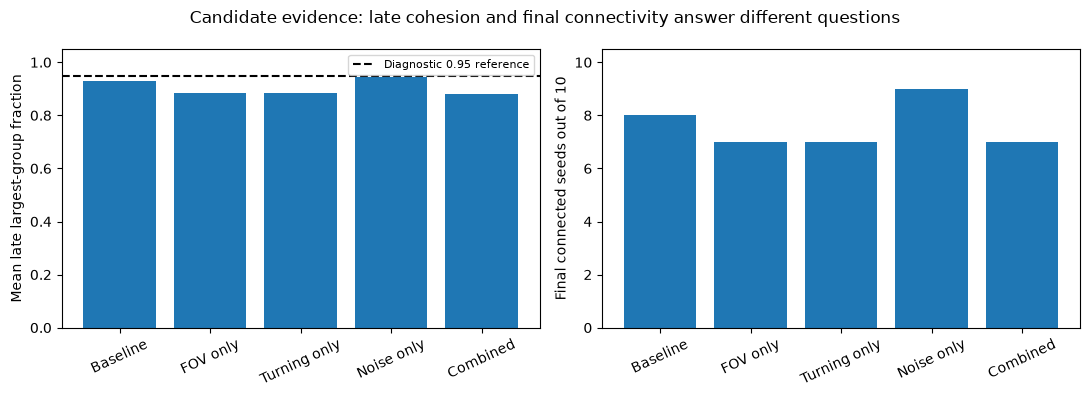

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = [name.split("—")[-1].strip() for name in candidates.index]
axes[0].bar(labels, candidates.MeanLateLargestGroupFraction)
axes[0].axhline(MIN_LATE_LGF, color="black", linestyle="--", label="Diagnostic 0.95 reference")
axes[0].set(ylabel="Mean late largest-group fraction", ylim=(0, 1.05))
axes[0].legend(fontsize=8)
axes[1].bar(labels, candidates.FinalConnectedSeeds)
axes[1].set(ylabel="Final connected seeds out of 10", ylim=(0, 10.5))
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
fig.suptitle("Candidate evidence: late cohesion and final connectivity answer different questions")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "06_candidate_selection.png", dpi=160, bbox_inches="tight")
plt.show()


In [6]:
fast = time_summary.loc[5.0]
coarse_rate = float(fast.loc[0.125, "MissedPassesPerSecond"])
fine_rate = float(fast.loc[0.03125, "MissedPassesPerSecond"])
readiness = {
    "RecommendedControl": {"speed": 1.0, "dt": 0.125, "fov_degrees": 360,
                           "max_turn_rate": None, "angular_noise": 0.0},
    "Recommendation": "Retain the unchanged baseline as the comparison control; do not promote a light-ready baseline yet.",
    "ReadyForLight": False,
    "Reason": "Unresolved assembly, timestep/decision-frequency sensitivity and incomplete joint high-speed extension validation.",
    "MeanMissedPassesPerSecondAtSpeed5": {"dt_0.125": coarse_rate, "dt_0.03125": fine_rate},
}
(DATA_DIR / "06_recommendation.json").write_text(json.dumps(readiness, indent=2) + "\n")
display(Markdown(f"""## Answers and recommendation

1. **One connected school?** The baseline ends connected in 8/10 seeds. Seeds 0 and 2 are disconnected throughout the observed 62.5 s; they never first assemble as a whole.
2. **How often does fragmentation occur?** Separate initial non-assembly from breakup. The ten baseline runs contain zero persistent splits after observed whole-group cohesion. Initial-disconnection episodes explain the persistent disconnected time. Subgroups can still reorganize internally.
3. **Walls?** Moving the same initial geometry into a larger arena reduces reflection rates, but seeds 0 and 2 remain disconnected. Walls are not required for the initial disconnected state and are not a sufficient explanation for its persistence. Later outcomes remain wall- and arena-sensitive.
4. **Timestep?** Both connectivity and order depend materially on timestep. The instantaneous-decision model is evaluated more often when dt decreases, so this experiment does not establish a unique continuous-time limit.
5. **Future maximum speed?** At speed 5, the mean geometric missed-pass rate falls from **{coarse_rate:.4f}/s** at dt=0.125 to **{fine_rate:.4f}/s** at dt=0.03125. No exact sampled overlaps were found. Missed zone encounters are not equivalent to fish-body collisions, and zero endpoint overlap is insufficient evidence of resolution.
6. **FOV, turning and noise?** Noise alone modestly improves this sample; FOV, turn limit and their combined setting do not uniformly improve cohesion. The combined condition reconnects the original two problem seeds while producing other failures. Selecting from only those two seeds would overfit the diagnosis.
7. **Literature parameters?** Social radii, 270° perception, 1.75 rad/update and 0.01-rad angular error are literature-informed. Raw social sums and repulsion priority follow the chosen social formulation.
8. **Implementation and diagnostic choices?** Overlap/tie resolution, reflecting walls, omnidirectional close repulsion, rate conversion, noise scaling, the 2.5-s persistence convention and the decision cutoffs require explicit disclosure. The connectivity graph remains undirected and distance-only even when perception is restricted.
9. **Numerical stability?** Executions are finite and bounded, but model-level timestep robustness is not established. A stable program is not the same as a resolved trajectory model.
10. **Ready for light?** **No.** Retain the current speed-1 baseline as a reproducible control, rather than changing defaults to whichever condition looks most cohesive. Treat dt=0.03125 as a refinement candidate, not a demonstrated converged solution. Before choosing a light-ready configuration, test further refinement and the chosen perception/turn/noise settings jointly at the future speed range, with consistent physical scaling and additional seeds.

The evidence supports **finite-range local interactions allowing persistent non-assembly**, with important boundary and discretization effects on the measured outcome. It does not establish an exclusive emergent-versus-artefact cause or biological validity. No light behaviour was implemented.
"""))


## Answers and recommendation

1. **One connected school?** The baseline ends connected in 8/10 seeds. Seeds 0 and 2 are disconnected throughout the observed 62.5 s; they never first assemble as a whole.
2. **How often does fragmentation occur?** Separate initial non-assembly from breakup. The ten baseline runs contain zero persistent splits after observed whole-group cohesion. Initial-disconnection episodes explain the persistent disconnected time. Subgroups can still reorganize internally.
3. **Walls?** Moving the same initial geometry into a larger arena reduces reflection rates, but seeds 0 and 2 remain disconnected. Walls are not required for the initial disconnected state and are not a sufficient explanation for its persistence. Later outcomes remain wall- and arena-sensitive.
4. **Timestep?** Both connectivity and order depend materially on timestep. The instantaneous-decision model is evaluated more often when dt decreases, so this experiment does not establish a unique continuous-time limit.
5. **Future maximum speed?** At speed 5, the mean geometric missed-pass rate falls from **11.4048/s** at dt=0.125 to **0.0896/s** at dt=0.03125. No exact sampled overlaps were found. Missed zone encounters are not equivalent to fish-body collisions, and zero endpoint overlap is insufficient evidence of resolution.
6. **FOV, turning and noise?** Noise alone modestly improves this sample; FOV, turn limit and their combined setting do not uniformly improve cohesion. The combined condition reconnects the original two problem seeds while producing other failures. Selecting from only those two seeds would overfit the diagnosis.
7. **Literature parameters?** Social radii, 270° perception, 1.75 rad/update and 0.01-rad angular error are literature-informed. Raw social sums and repulsion priority follow the chosen social formulation.
8. **Implementation and diagnostic choices?** Overlap/tie resolution, reflecting walls, omnidirectional close repulsion, rate conversion, noise scaling, the 2.5-s persistence convention and the decision cutoffs require explicit disclosure. The connectivity graph remains undirected and distance-only even when perception is restricted.
9. **Numerical stability?** Executions are finite and bounded, but model-level timestep robustness is not established. A stable program is not the same as a resolved trajectory model.
10. **Ready for light?** **No.** Retain the current speed-1 baseline as a reproducible control, rather than changing defaults to whichever condition looks most cohesive. Treat dt=0.03125 as a refinement candidate, not a demonstrated converged solution. Before choosing a light-ready configuration, test further refinement and the chosen perception/turn/noise settings jointly at the future speed range, with consistent physical scaling and additional seeds.

The evidence supports **finite-range local interactions allowing persistent non-assembly**, with important boundary and discretization effects on the measured outcome. It does not establish an exclusive emergent-versus-artefact cause or biological validity. No light behaviour was implemented.


## Reference roles

[Couzin et al. (2002)](https://doi.org/10.1006/jtbi.2002.3065) supplies the local social-zone framework. [Puckett et al. (2018)](https://doi.org/10.1038/s41598-018-26037-9) and its supplement inform the tested social extensions and the future speed range. [Tunstrøm et al. (2013)](https://doi.org/10.1371/journal.pcbi.1002915) motivates order measurements, which do not replace connectivity. [Katz et al. (2011)](https://doi.org/10.1073/pnas.1107583108) motivates treating explicit orientation matching as a model assumption. [Berdahl et al. (2013)](https://doi.org/10.1126/science.1225883) informs the later scalar-light mechanism; [Hein et al. (2015)](https://doi.org/10.7554/eLife.10955) is conceptual support for alternative formulations, not a replacement model used here.

Stop at this recommendation. The environment/light stage requires review of these results first.
